# Práctica 1 - Preparación de datos
## Sistemas de Aprendizaje Automático
**Alumno:** Fernando Yucsan Chang Cam  
**Curso:** 2025-26  
**Centro:** I.E.S. Camas

---

## Objetivo de la práctica

En esta práctica preparamos el dataset del Titanic para su posterior análisis mediante Machine Learning. El proceso incluye:

1. Importación y limpieza de datos
2. Codificación de variables categóricas
3. Eliminación de datos inválidos
4. Análisis estadístico exploratorio
5. Escalamiento de datos
6. Exportación del dataset procesado

**Dataset:** 891 pasajeros del Titanic con información sobre supervivencia, edad, clase, sexo, etc.

---

# Tarea 1: Importación de librerías y carga del dataset

En esta primera tarea vamos a:
1. **Importar las librerías necesarias:** pandas (manipulación de datos), numpy (operaciones numéricas), matplotlib (visualización)
2. **Cargar el dataset del Titanic** desde una URL de GitHub
3. **Eliminar columnas redundantes** que duplican información

El dataset del Titanic contiene información de 891 pasajeros con múltiples atributos. Nuestro objetivo es preparar estos datos para entrenar modelos de machine learning que predigan la supervivencia.

### Buenas prácticas aplicadas:
- **Normalización de nombres de columnas** a minúsculas para evitar errores
- **Uso de numpy arrays** para manipulación eficiente de listas
- **Verificación visual** de los datos en cada paso

1. Tarea 1: Importación de librerías, carga del dataset y eliminación de columnas redundantes.

In [46]:
#Importación de Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
midataframe = pd.read_csv(url)

print("*"*15 , " Datos al Bruto", "*"*15)
print(midataframe)

# Normalizar columnas al inicio
midataframe.columns = midataframe.columns.str.lower()
print(f"Columnas después de normalizar: {midataframe.columns.tolist()}")

#1.3. Se eliminarán las columnas Class, Who, Adult_male, Embark_town y Alive.

columnas_a_eliminar = ["Class", "Who", "Adult_male", "Embark_town", "Alive"]
# Convertir a numpy array
columnas_a_eliminar_np = np.array(columnas_a_eliminar)

# Pasar todo a minúsculas
columnasEliminaLowerCase = np.char.lower(columnas_a_eliminar_np)

#elimino columnas
midataframe = midataframe.drop(columns=columnasEliminaLowerCase, errors="ignore")

print("*"*15 , " Datos resultado de eliminar columnas", "*"*15)
print(midataframe)


***************  Datos al Bruto ***************
     survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
0           0       3    male  22.0      1      0   7.2500        S   Third   
1           1       1  female  38.0      1      0  71.2833        C   First   
2           1       3  female  26.0      0      0   7.9250        S   Third   
3           1       1  female  35.0      1      0  53.1000        S   First   
4           0       3    male  35.0      0      0   8.0500        S   Third   
..        ...     ...     ...   ...    ...    ...      ...      ...     ...   
886         0       2    male  27.0      0      0  13.0000        S  Second   
887         1       1  female  19.0      0      0  30.0000        S   First   
888         0       3  female   NaN      1      2  23.4500        S   Third   
889         1       1    male  26.0      0      0  30.0000        C   First   
890         0       3    male  32.0      0      0   7.7500        Q   Third   

   

2. Tarea 2: Codificación de columnas de texto:

2.1. La columna sex debe codificarse de forma numérica como entero, siendo 0 para hombre y 1 para mujer.

In [47]:
# Codificar Sex: 0 para female, 1 para male
map_sex = {
    "male": 0,
    "female": 1
}
midataframe["sex"] = midataframe["sex"].map(map_sex).astype('Int64')

print("*"*15 , " Datos resultado de codificar Sex", "*"*15)
print(midataframe["sex"])

***************  Datos resultado de codificar Sex ***************
0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    1
889    0
890    0
Name: sex, Length: 891, dtype: Int64


### Resultado Tarea 1

Hemos eliminado **5 columnas redundantes**:
- `class` → Duplica información de `pclass`
- `who` → Duplica información de `sex`
- `adult_male` → Derivable de `sex` y `age`
- `embark_town` → Duplica información de `embarked`
- `alive` → Duplica información de `survived`

**Columnas restantes:** 10 columnas relevantes para el análisis.

---

# Tarea 2: Codificación de variables categóricas

Los algoritmos de Machine Learning trabajan con números, no con texto. Por eso debemos convertir las columnas categóricas a valores numéricos mediante **codificación ordinal**.

### Variables a codificar:

| Columna | Tipo original | Codificación |
|---------|---------------|--------------|
| `sex` | texto (male/female) | male=0, female=1 |
| `embarked` | texto (C/Q/S) | C=0, Q=1, S=2 |
| `deck` | texto (A-G) | A=0, B=1, ..., G=6 |
| `alone` | booleano (True/False) | False=0, True=1 |

**Nota técnica:** Usamos el tipo `Int64` (con mayúscula) en lugar de `int64` porque permite valores nulos (NaN) sin causar errores durante la limpieza posterior.

2.2. La columna Embarked debe codificarse de forma numérica como entero, siendo 0 para Cherbourg, 1 para Queenstown y 2 para Southampton.

In [48]:
map_embarked = {
    "C": 0,   # Cherbourg
    "Q": 1,   # Queenstown
    "S": 2    # Southampton
}

midataframe["embarked"] = midataframe["embarked"].replace(map_embarked).astype('Int64')

print("*"*15 , " Datos resultado de codificar Embarked", "*"*15)
print(midataframe["embarked"])

***************  Datos resultado de codificar Embarked ***************
0      2
1      0
2      2
3      2
4      2
      ..
886    2
887    2
888    2
889    0
890    1
Name: embarked, Length: 891, dtype: Int64


/tmp/ipython-input-198467587.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  midataframe["embarked"] = midataframe["embarked"].replace(map_embarked).astype('Int64')


2.3. La columna Deck debe codificarse de forma numérica como entero, siendo 0 para A, 1 para B, … y 6 para G.

In [49]:
#2.3 deck
map_deck = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4,
    "F": 5,
    "G": 6
}

#midataframe["deck"] = midataframe["deck"].replace(map_deck).astype('Int64')
midataframe["deck"] = midataframe["deck"].map(map_deck).astype('Int64')
print(midataframe["deck"])



0      <NA>
1         2
2      <NA>
3         2
4      <NA>
       ... 
886    <NA>
887       1
888    <NA>
889       2
890    <NA>
Name: deck, Length: 891, dtype: Int64


2.4. La columna Alone debe codificarse de forma numérica como entero, siendo 0 si no viajaba solo y 1 si viajaba solo.

In [50]:
#2.4. Codificar Alone
map_alone = {
    False: 0,  # No viajaba solo
    True: 1    # Viajaba solo
}
#1 usando map como antes
midataframe["alone"] = midataframe["alone"].map(map_alone).astype('Int64')

#2 usando astype
#midataframe["alone"] = midataframe["alone"].astype('Int64')

print("*"*15 , " Datos resultado de codificar Alone", "*"*15)
print(midataframe["alone"])

***************  Datos resultado de codificar Alone ***************
0      0
1      0
2      1
3      0
4      1
      ..
886    1
887    1
888    0
889    1
890    1
Name: alone, Length: 891, dtype: Int64


### Resultado Tarea 2

Las 4 columnas categóricas han sido correctamente codificadas a valores numéricos. Los datos están listos para la siguiente fase: **limpieza de datos inválidos**.

---

# Tarea 3: Limpieza de datos inválidos y fuera de rango

Los datos del mundo real suelen tener problemas de calidad:
- **Valores nulos (NaN):** Información faltante o no registrada
- **Valores fuera de rango:** Datos incorrectos o atípicos que violan las restricciones del dominio

### Proceso de limpieza en 2 pasos:

**Paso 1 - Eliminar columnas con >25% de datos inválidos:**
- Analizamos cada columna individualmente
- Contamos datos nulos + datos fuera de rango válido
- Si el porcentaje supera el 25%, eliminamos la columna completa

**Paso 2 - Eliminar filas con datos inválidos:**
- En las columnas restantes, eliminamos todas las filas que contengan:
  - Valores nulos en cualquier columna
  - Valores fuera del rango válido especificado

### Rangos válidos definidos:

| Atributo | Rango válido | Descripción |
|----------|-------------|-------------|
| `survived` | {0, 1} | 0=No sobrevivió, 1=Sobrevivió |
| `pclass` | {1, 2, 3} | Clase del billete |
| `sex` | {0, 1} | 0=male, 1=female |
| `age` | [0-100] | Edad en años |
| `sibsp` | [0-10] | Hermanos/cónyuges a bordo |
| `parch` | [0-10] | Padres/hijos a bordo |
| `fare` | >0 | Tarifa pagada (libras) |
| `embarked` | {0, 1, 2} | Puerto de embarque |
| `deck` | {0, 1, 2, 3, 4, 5, 6} | Cubierta (A-G) |
| `alone` | {0, 1} | Viajaba solo |

3. Tarea 3: Limpieza de datos vacíos y de datos fuera de rango
Considera el siguiente rango como el rango correcto de los atributos:

○ Survived: {0, 1}

○ Pclass: {1, 2, 3}

○ Sex: {0, 1}

○ Age: [0-100]

○ SibSp: [0-10]

○ Parch: [0-10]

○ Fare: >0

○ Embarked {0, 1,2}

○ Deck: {0, 1, 2, 3, 4, 5, 6}

○ Alone: {0, 1}

3.1. Se consideran datos inválidos aquellos que están vacíos, o que tienen un valor fuera del rango indicado. Para cada uno de los atributos, calcula el número de elementos inválidos (puedes usar el método pandas.DataFrame.info).
○ Si en alguna de las columnas el porcentaje de datos inválidos es superior al 25%, elimina esa columna completa.
○ Después de eso, en el resto, elimina las filas completas que tengan algún atributo inválido.

In [51]:
"""3.1. Detección y eliminación de datos inválidos por columna"""

print("\n" + "="*60)
print(" PASO 3.1: ANÁLISIS Y LIMPIEZA DE DATOS INVÁLIDOS")
print("="*60)

# Definir rangos válidos para cada columna
rangos_validos = {
    'survived': [0, 1],
    'pclass': [1, 2, 3],
    'sex': [0, 1],
    'age': [0, 100],
    'sibsp': [0, 10],
    'parch': [0, 10],
    'fare': (0, float('inf')),  # Mayor que 0, al infinito
    'embarked': [0, 1, 2],
    'deck': [0, 1, 2, 3, 4, 5, 6],
    'alone': [0, 1]
}

# Calcular datos inválidos por columna
print("\n--- ANÁLISIS DE DATOS INVÁLIDOS POR COLUMNA ---\n")
total_filas = len(midataframe)
columnas_a_eliminar = []

for columna in midataframe.columns:
    if columna in rangos_validos:
        # Contar nulos
        nulos = midataframe[columna].isna().sum()

        # Contar fuera de rango según el tipo de validación
        if columna == 'fare':
            # Fare debe ser > 0
            fuera_rango = ((midataframe[columna] <= 0) & midataframe[columna].notna()).sum()
        elif columna == 'sex':
            # Sex debe ser 'male' o 'female'
            fuera_rango = (~midataframe[columna].isin(rangos_validos[columna]) & midataframe[columna].notna()).sum()
        elif columna in ['age', 'sibsp', 'parch']:
            # Rango continuo [min, max]
            min_val, max_val = rangos_validos[columna]
            fuera_rango = (((midataframe[columna] < min_val) | (midataframe[columna] > max_val)) & midataframe[columna].notna()).sum()
        else:
            # Valores discretos (survived, pclass, embarked, deck, alone)
            fuera_rango = (~midataframe[columna].isin(rangos_validos[columna]) & midataframe[columna].notna()).sum()

        # Total de inválidos
        invalidos = nulos + fuera_rango
        porcentaje = (invalidos / total_filas) * 100

        print(f"{columna.upper()}:")
        print(f"  - Valores nulos: {nulos}")
        print(f"  - Fuera de rango: {fuera_rango}")
        print(f"  - Total inválidos: {invalidos}")
        print(f"  - Porcentaje: {porcentaje:.2f}%")

        # Si supera el 25%, marcar para eliminar
        if porcentaje > 25:
            print(f"COLUMNA MARCADA PARA ELIMINACIÓN (>{25}%)")
            columnas_a_eliminar.append(columna)

        print()

# Eliminar columnas con >25% de datos inválidos
if columnas_a_eliminar:
    print(f"\n--- ELIMINANDO COLUMNAS CON >25% DE DATOS INVÁLIDOS ---")
    print(f"Columnas a eliminar: {columnas_a_eliminar}")
    midataframe = midataframe.drop(columns=columnas_a_eliminar)
    print(f"Columnas eliminadas exitosamente.\n")
else:
    print(f"\n✓ Ninguna columna supera el 25% de datos inválidos.\n")

print(f"Columnas restantes: {midataframe.columns.tolist()}")
print(f"Total de filas antes de eliminar filas inválidas: {len(midataframe)}")

# Ahora eliminar filas con cualquier dato inválido en las columnas restantes
print("\n--- ELIMINANDO FILAS CON DATOS INVÁLIDOS ---\n")
filas_antes = len(midataframe)

# Crear máscara de filas válidas
mascara_valida = pd.Series([True] * len(midataframe), index=midataframe.index)

for columna in midataframe.columns:
    if columna in rangos_validos:
        if columna == 'fare':
            # Fare debe ser > 0 y no nulo
            mascara_valida &= (midataframe[columna] > 0) & midataframe[columna].notna()
        elif columna == 'sex':
            # Sex debe ser válido y no nulo
            mascara_valida &= midataframe[columna].isin(rangos_validos[columna]) & midataframe[columna].notna()
        elif columna in ['age', 'sibsp', 'parch']:
            # Rango continuo y no nulo
            min_val, max_val = rangos_validos[columna]
            mascara_valida &= (midataframe[columna] >= min_val) & (midataframe[columna] <= max_val) & midataframe[columna].notna()
        else:
            # Valores discretos y no nulos
            mascara_valida &= midataframe[columna].isin(rangos_validos[columna]) & midataframe[columna].notna()

# Aplicar la máscara
midataframe = midataframe[mascara_valida].reset_index(drop=True)

filas_eliminadas = filas_antes - len(midataframe)
print(f"Filas eliminadas: {filas_eliminadas}")
print(f"Total de filas finales: {len(midataframe)}")

# Verificación final
print("\n--- VERIFICACIÓN FINAL ---")
print(f"Valores nulos restantes:")
print(midataframe.isnull().sum())
print("\n" + "="*60)
print(midataframe.head(10))


 PASO 3.1: ANÁLISIS Y LIMPIEZA DE DATOS INVÁLIDOS

--- ANÁLISIS DE DATOS INVÁLIDOS POR COLUMNA ---

SURVIVED:
  - Valores nulos: 0
  - Fuera de rango: 0
  - Total inválidos: 0
  - Porcentaje: 0.00%

PCLASS:
  - Valores nulos: 0
  - Fuera de rango: 0
  - Total inválidos: 0
  - Porcentaje: 0.00%

SEX:
  - Valores nulos: 0
  - Fuera de rango: 0
  - Total inválidos: 0
  - Porcentaje: 0.00%

AGE:
  - Valores nulos: 177
  - Fuera de rango: 0
  - Total inválidos: 177
  - Porcentaje: 19.87%

SIBSP:
  - Valores nulos: 0
  - Fuera de rango: 0
  - Total inválidos: 0
  - Porcentaje: 0.00%

PARCH:
  - Valores nulos: 0
  - Fuera de rango: 0
  - Total inválidos: 0
  - Porcentaje: 0.00%

FARE:
  - Valores nulos: 0
  - Fuera de rango: 15
  - Total inválidos: 15
  - Porcentaje: 1.68%

EMBARKED:
  - Valores nulos: 2
  - Fuera de rango: 0
  - Total inválidos: 2
  - Porcentaje: 0.22%

DECK:
  - Valores nulos: 688
  - Fuera de rango: 0
  - Total inválidos: 688
  - Porcentaje: 77.22%
COLUMNA MARCADA PARA EL

### Resultado Tarea 3

**Columna eliminada:** `deck` (>75% de valores nulos)  
**Motivo:** En el Titanic, la información de cubierta solo estaba disponible para pasajeros de primera clase y algunos de segunda. Para tercera clase, este dato era mayoritariamente desconocido.

**Filas limpias:** El dataset final contiene solo filas con datos válidos en todas las columnas restantes.

**Importancia:** Este proceso garantiza que los modelos de ML se entrenen con datos de calidad, evitando predicciones erróneas por datos corruptos o faltantes.

---

# Tarea 4: Análisis estadístico exploratorio

Antes de aplicar algoritmos de Machine Learning, es crucial **entender los datos**. El análisis exploratorio nos ayuda a:
- Identificar patrones y relaciones entre variables
- Detectar sesgos en los datos
- Comprender qué factores influyeron en la supervivencia
- Validar la calidad de los datos

Realizaremos 3 análisis:
1. **Sex vs Survived:** ¿Influyó el sexo en la supervivencia?
2. **Pclass vs Survived:** ¿Influyó la clase socioeconómica?
3. **Análisis de edad:** Distribución, estadísticas y detección de outliers

4. Tarea 4: Cálculos estadísticos básicos.

4.1. Haz un análisis estadístico relacionando el atributo Sex con el target (Survived).


 TAREA 4.1: ANÁLISIS SEX vs SURVIVED

--- ANÁLISIS USANDO GROUPBY ---

Conteo de personas por Survived y Sex:
survived  sex
0         0      354
          1       64
1         0       92
          1      195
dtype: int64


--- DATOS NUMÉRICOS DETALLADOS ---

NO SOBREVIVIÓ (Survived = 0):
  - Male (sex=0): 354 personas
  - Female (sex=1): 64 personas
  - Total: 418

SOBREVIVIÓ (Survived = 1):
  - Male (sex=0): 92 personas
  - Female (sex=1): 195 personas
  - Total: 287


--- TASA DE SUPERVIVENCIA POR SEXO ---

Tasa de supervivencia:
  - Male (sex=0): 20.63%
  - Female (sex=1): 75.29%



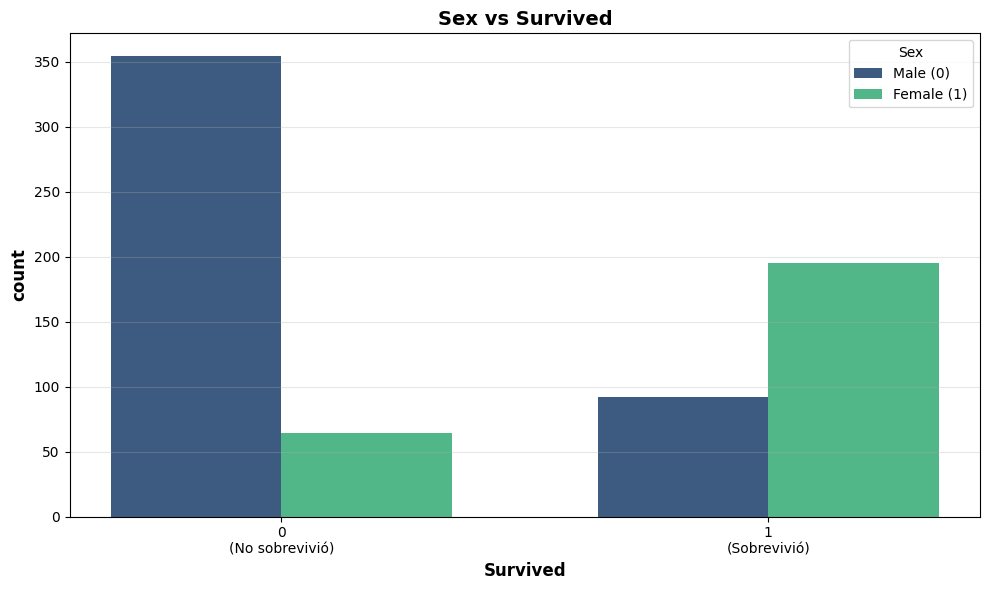

In [52]:
"""4.1. Análisis estadístico relacionando Sex con Survived"""

print("\n" + "="*60)
print(" TAREA 4.1: ANÁLISIS SEX vs SURVIVED")
print("="*60)

# --- ANÁLISIS CON GROUPBY ---
print("\n--- ANÁLISIS USANDO GROUPBY ---\n")

# Agrupar por survived y sex, y contar cuántos hay en cada grupo
conteo = midataframe.groupby(['survived', 'sex']).size()
print("Conteo de personas por Survived y Sex:")
print(conteo)
print()

# --- DATOS NUMÉRICOS DETALLADOS ---
print("\n--- DATOS NUMÉRICOS DETALLADOS ---\n")

# Extraer los valores del conteo
# RECUERDA: male=0, female=1 (según tu codificación correcta)
survived_0_male = conteo[0, 0]      # survived=0, sex=0 (male)
survived_0_female = conteo[0, 1]    # survived=0, sex=1 (female)
survived_1_male = conteo[1, 0]      # survived=1, sex=0 (male)
survived_1_female = conteo[1, 1]    # survived=1, sex=1 (female)

print("NO SOBREVIVIÓ (Survived = 0):")
print(f"  - Male (sex=0): {survived_0_male} personas")
print(f"  - Female (sex=1): {survived_0_female} personas")
print(f"  - Total: {survived_0_male + survived_0_female}")
print()

print("SOBREVIVIÓ (Survived = 1):")
print(f"  - Male (sex=0): {survived_1_male} personas")
print(f"  - Female (sex=1): {survived_1_female} personas")
print(f"  - Total: {survived_1_male + survived_1_female}")
print()

# --- TASA DE SUPERVIVENCIA POR SEXO ---
print("\n--- TASA DE SUPERVIVENCIA POR SEXO ---\n")

# Agrupar por sex y calcular la media de survived
tasa_supervivencia = midataframe.groupby('sex')['survived'].mean() * 100

print("Tasa de supervivencia:")
print(f"  - Male (sex=0): {tasa_supervivencia[0]:.2f}%")
print(f"  - Female (sex=1): {tasa_supervivencia[1]:.2f}%")
print()

# --- GRÁFICO DE BARRAS AGRUPADAS ---

# Datos para el gráfico
categorias = ['0\n(No sobrevivió)', '1\n(Sobrevivió)']
male_counts = [survived_0_male, survived_1_male]
female_counts = [survived_0_female, survived_1_female]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(10, 6))

# Ancho de las barras y posiciones
ancho = 0.35
x = np.arange(len(categorias))

# Crear barras
barras_male = ax.bar(x - ancho/2, male_counts, ancho,
                      label='Male (0)', color='#3d5a80')
barras_female = ax.bar(x + ancho/2, female_counts, ancho,
                        label='Female (1)', color='#52b788')

# Personalizar el gráfico
ax.set_xlabel('Survived', fontsize=12, fontweight='bold')
ax.set_ylabel('count', fontsize=12, fontweight='bold')
ax.set_title('Sex vs Survived', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categorias, fontsize=10)
ax.legend(title='Sex', fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Ajustar diseño
plt.tight_layout()
plt.show()

### Interpretación: Sexo y Supervivencia

**Hallazgos clave:**
- Las **mujeres** tuvieron una tasa de supervivencia significativamente mayor que los hombres
- Esto refleja la política de evacuación **"mujeres y niños primero"** aplicada durante el hundimiento del Titanic
- La diferencia es estadísticamente muy significativa


 TAREA 4.2: ANÁLISIS PCLASS vs SURVIVED

--- ANÁLISIS USANDO GROUPBY ---

Conteo de personas por Survived y Pclass:
survived  pclass
0         1          61
          2          90
          3         267
1         1         120
          2          83
          3          84
dtype: int64


--- DATOS NUMÉRICOS DETALLADOS ---

NO SOBREVIVIÓ (Survived = 0):
  - Primera Clase (pclass=1): 61 personas
  - Segunda Clase (pclass=2): 90 personas
  - Tercera Clase (pclass=3): 267 personas
  - Total: 418

SOBREVIVIÓ (Survived = 1):
  - Primera Clase (pclass=1): 120 personas
  - Segunda Clase (pclass=2): 83 personas
  - Tercera Clase (pclass=3): 84 personas
  - Total: 287


--- TASA DE SUPERVIVENCIA POR CLASE ---

Tasa de supervivencia por clase:
  - Primera Clase (pclass=1): 66.30%
  - Segunda Clase (pclass=2): 47.98%
  - Tercera Clase (pclass=3): 23.93%



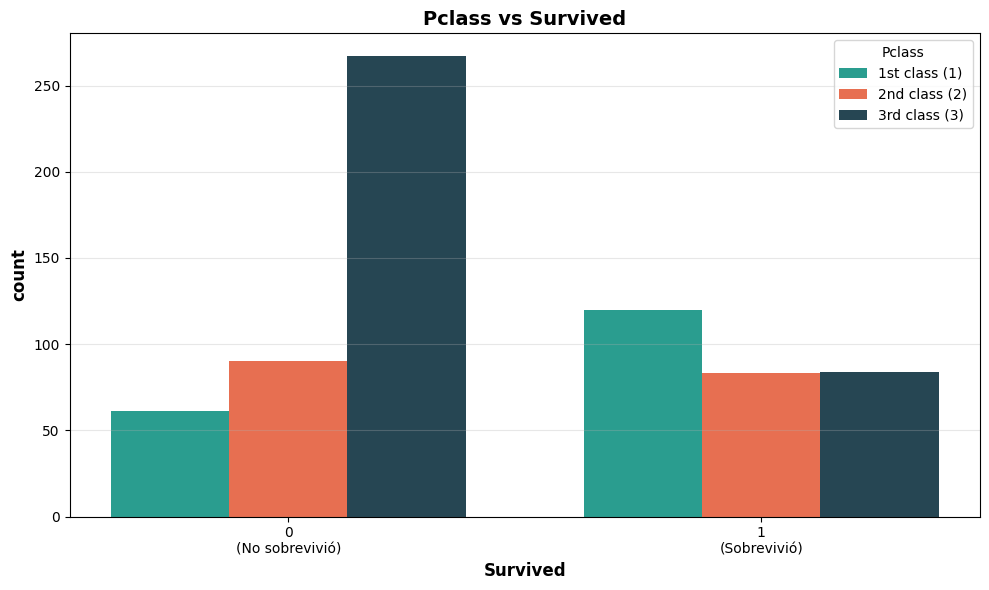

In [53]:
"""4.2. Análisis estadístico relacionando Pclass con Survived"""

print("\n" + "="*60)
print(" TAREA 4.2: ANÁLISIS PCLASS vs SURVIVED")
print("="*60)

# --- ANÁLISIS CON GROUPBY ---
print("\n--- ANÁLISIS USANDO GROUPBY ---\n")

# Agrupar por survived y pclass, y contar cuántos hay en cada grupo
conteo_pclass = midataframe.groupby(['survived', 'pclass']).size()
print("Conteo de personas por Survived y Pclass:")
print(conteo_pclass)
print()

# --- DATOS NUMÉRICOS DETALLADOS ---
print("\n--- DATOS NUMÉRICOS DETALLADOS ---\n")

# Extraer los valores del conteo
survived_0_class1 = conteo_pclass[0, 1]  # survived=0, pclass=1
survived_0_class2 = conteo_pclass[0, 2]  # survived=0, pclass=2
survived_0_class3 = conteo_pclass[0, 3]  # survived=0, pclass=3

survived_1_class1 = conteo_pclass[1, 1]  # survived=1, pclass=1
survived_1_class2 = conteo_pclass[1, 2]  # survived=1, pclass=2
survived_1_class3 = conteo_pclass[1, 3]  # survived=1, pclass=3

print("NO SOBREVIVIÓ (Survived = 0):")
print(f"  - Primera Clase (pclass=1): {survived_0_class1} personas")
print(f"  - Segunda Clase (pclass=2): {survived_0_class2} personas")
print(f"  - Tercera Clase (pclass=3): {survived_0_class3} personas")
print(f"  - Total: {survived_0_class1 + survived_0_class2 + survived_0_class3}")
print()

print("SOBREVIVIÓ (Survived = 1):")
print(f"  - Primera Clase (pclass=1): {survived_1_class1} personas")
print(f"  - Segunda Clase (pclass=2): {survived_1_class2} personas")
print(f"  - Tercera Clase (pclass=3): {survived_1_class3} personas")
print(f"  - Total: {survived_1_class1 + survived_1_class2 + survived_1_class3}")
print()

# --- TASA DE SUPERVIVENCIA POR CLASE ---
print("\n--- TASA DE SUPERVIVENCIA POR CLASE ---\n")

# Agrupar por pclass y calcular la media de survived
tasa_supervivencia_pclass = midataframe.groupby('pclass')['survived'].mean() * 100

print("Tasa de supervivencia por clase:")
print(f"  - Primera Clase (pclass=1): {tasa_supervivencia_pclass[1]:.2f}%")
print(f"  - Segunda Clase (pclass=2): {tasa_supervivencia_pclass[2]:.2f}%")
print(f"  - Tercera Clase (pclass=3): {tasa_supervivencia_pclass[3]:.2f}%")
print()

# --- GRÁFICO DE BARRAS AGRUPADAS ---

# Datos para el gráfico
categorias = ['0\n(No sobrevivió)', '1\n(Sobrevivió)']
class1_counts = [survived_0_class1, survived_1_class1]
class2_counts = [survived_0_class2, survived_1_class2]
class3_counts = [survived_0_class3, survived_1_class3]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(10, 6))

# Ancho de las barras y posiciones
ancho = 0.25
x = np.arange(len(categorias))

# Crear barras para cada clase
barras_class1 = ax.bar(x - ancho, class1_counts, ancho,
                        label='1st class (1)', color='#2a9d8f')
barras_class2 = ax.bar(x, class2_counts, ancho,
                        label='2nd class (2)', color='#e76f51')
barras_class3 = ax.bar(x + ancho, class3_counts, ancho,
                        label='3rd class (3)', color='#264653')

# Personalizar el gráfico
ax.set_xlabel('Survived', fontsize=12, fontweight='bold')
ax.set_ylabel('count', fontsize=12, fontweight='bold')
ax.set_title('Pclass vs Survived', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categorias, fontsize=10)
ax.legend(title='Pclass', fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Ajustar diseño
plt.tight_layout()
plt.show()

### Interpretación: Clase socioeconómica y Supervivencia

**Hallazgos clave:**
- **Primera clase:** Mayor tasa de supervivencia
- **Tercera clase:** Menor tasa de supervivencia
- Existe una **clara correlación entre clase social y supervivencia**

**Factores que explican esta diferencia:**
1. **Ubicación de camarotes:** Primera clase en cubiertas superiores, más cerca de los botes salvavidas
2. **Acceso prioritario:** Los pasajeros de primera clase tuvieron acceso más rápido a la cubierta de botes
3. **Información:** Los pasajeros de primera clase fueron informados antes sobre la emergencia
4. **Barreras físicas:** Puertas cerradas limitaron el acceso de tercera clase a las cubiertas superiores

4.3. Haz un análisis estadístico de la edad de los pasajeros que contenga, al menos, la media, la mediana, la desviación típica, el mínimo, el máximo, y los cuartiles Q1, Q2 y Q3. Representa la distribución de la edad de forma gráfica.


 TAREA 4.3: ANÁLISIS ESTADÍSTICO DE LA EDAD

--- INFORMACIÓN GENERAL ---
Total de datos de edad: 705


----------------------------------------------------------------------
 1. ESTADÍSTICAS DESCRIPTIVAS
----------------------------------------------------------------------
Media:              29.59 años
Mediana (Q2):       28.00 años
Desviación típica:  14.51 años
Mínimo:             0.42 años
Máximo:             80.00 años

--- CUARTILES ---
Q1 (25%):           20.00 años
Q2 (50%):           28.00 años
Q3 (75%):           38.00 años
IQR (Q3-Q1):        18.00 años


----------------------------------------------------------------------
 2. GRÁFICO DE DISTRIBUCIÓN DE EDADES
----------------------------------------------------------------------


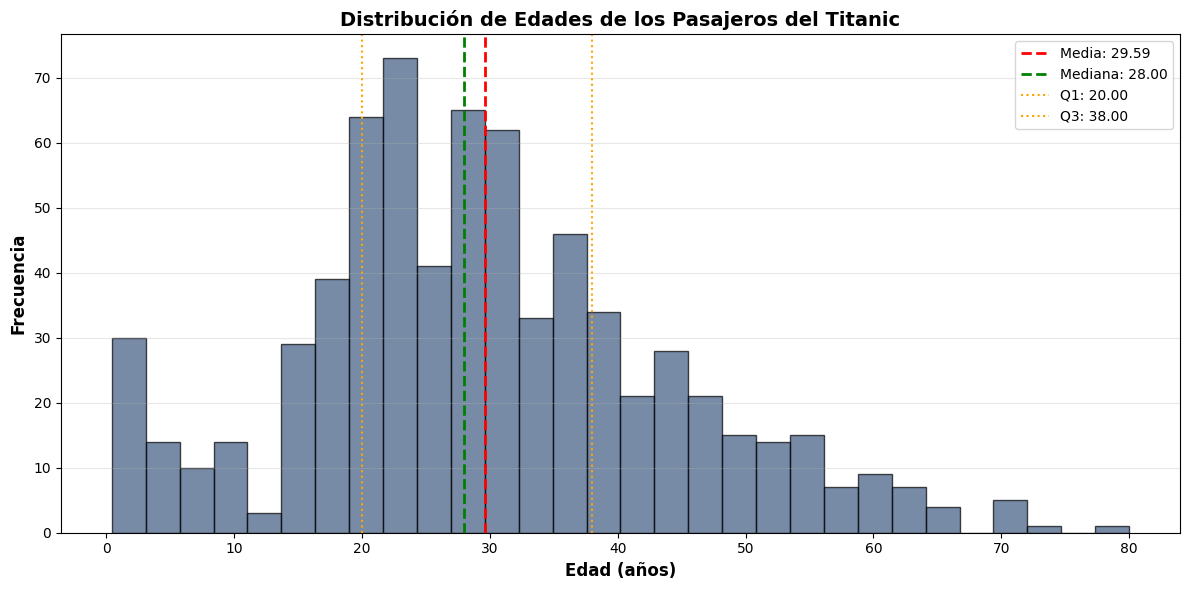


----------------------------------------------------------------------
 3.1. DETECCIÓN DE OUTLIERS - CRITERIO CHAUVENET
----------------------------------------------------------------------
Alfa = 0.000709
Z_(1-alfa/2) = 3.3860
Banda válida = [-19.56, 78.73]

  El dato[492] = 80.00 años es un outlier

Total de outliers detectados: 1


----------------------------------------------------------------------
 3.2. DETECCIÓN DE OUTLIERS - MÉTODO IQR (k=1.5)
----------------------------------------------------------------------
Q1 = 20.00
Q3 = 38.00
IQR = 18.00
k = 1.5
Banda válida = [-7.00, 65.00]

  El dato[25] = 66.00 años es un outlier
  El dato[73] = 71.00 años es un outlier
  El dato[90] = 70.50 años es un outlier
  El dato[388] = 71.00 años es un outlier
  El dato[492] = 80.00 años es un outlier
  El dato[525] = 70.00 años es un outlier
  El dato[586] = 70.00 años es un outlier
  El dato[670] = 74.00 años es un outlier

Total de outliers detectados: 8


-----------------------------

In [54]:
"""4.3. Análisis estadístico de la edad de los pasajeros"""

import scipy.stats as st

print("\n" + "="*70)
print(" TAREA 4.3: ANÁLISIS ESTADÍSTICO DE LA EDAD")
print("="*70)

# --- PREPARAR DATOS ---
# Extraer la columna age como numpy array (sin valores nulos ya limpiados antes)
datos_age = midataframe['age'].values

print(f"\n--- INFORMACIÓN GENERAL ---")
print(f"Total de datos de edad: {len(datos_age)}")
print()

# --- 1. ESTADÍSTICAS BÁSICAS ---
print("\n" + "-"*70)
print(" 1. ESTADÍSTICAS DESCRIPTIVAS")
print("-"*70)

media = np.mean(datos_age)
mediana = np.median(datos_age)
desviacion = np.std(datos_age)
minimo = np.min(datos_age)
maximo = np.max(datos_age)

# Cuartiles
Q1 = np.quantile(datos_age, 0.25)
Q2 = np.quantile(datos_age, 0.50)  # Q2 = mediana
Q3 = np.quantile(datos_age, 0.75)

print(f"Media:              {media:.2f} años")
print(f"Mediana (Q2):       {mediana:.2f} años")
print(f"Desviación típica:  {desviacion:.2f} años")
print(f"Mínimo:             {minimo:.2f} años")
print(f"Máximo:             {maximo:.2f} años")
print()
print("--- CUARTILES ---")
print(f"Q1 (25%):           {Q1:.2f} años")
print(f"Q2 (50%):           {Q2:.2f} años")
print(f"Q3 (75%):           {Q3:.2f} años")
print(f"IQR (Q3-Q1):        {Q3-Q1:.2f} años")
print()

# --- 2. GRÁFICO DE DISTRIBUCIÓN ---
print("\n" + "-"*70)
print(" 2. GRÁFICO DE DISTRIBUCIÓN DE EDADES")
print("-"*70)

fig, ax = plt.subplots(figsize=(12, 6))

# Histograma
ax.hist(datos_age, bins=30, color='#3d5a80', alpha=0.7, edgecolor='black')

# Líneas verticales para estadísticas clave
ax.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Media: {media:.2f}')
ax.axvline(mediana, color='green', linestyle='--', linewidth=2, label=f'Mediana: {mediana:.2f}')
ax.axvline(Q1, color='orange', linestyle=':', linewidth=1.5, label=f'Q1: {Q1:.2f}')
ax.axvline(Q3, color='orange', linestyle=':', linewidth=1.5, label=f'Q3: {Q3:.2f}')

# Personalización
ax.set_xlabel('Edad (años)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frecuencia', fontsize=12, fontweight='bold')
ax.set_title('Distribución de Edades de los Pasajeros del Titanic', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- 3. DETECCIÓN DE OUTLIERS ---

# --- 3.1 CRITERIO CHAUVENET ---
print("\n" + "-"*70)
print(" 3.1. DETECCIÓN DE OUTLIERS - CRITERIO CHAUVENET")
print("-"*70)

alfa = 1 / (2 * len(datos_age))
Z_alfa = st.norm.ppf(1 - alfa/2)

xL = np.mean(datos_age) - Z_alfa * np.std(datos_age)
xU = np.mean(datos_age) + Z_alfa * np.std(datos_age)

print(f"Alfa = {alfa:.6f}")
print(f"Z_(1-alfa/2) = {Z_alfa:.4f}")
print(f"Banda válida = [{xL:.2f}, {xU:.2f}]")
print()

outliers_chauvenet = []
for i in range(len(datos_age)):
    if datos_age[i] < xL or datos_age[i] > xU:
        outliers_chauvenet.append((i, datos_age[i]))
        print(f"  El dato[{i}] = {datos_age[i]:.2f} años es un outlier")

if len(outliers_chauvenet) == 0:
    print("  No se detectaron outliers con este criterio")

print(f"\nTotal de outliers detectados: {len(outliers_chauvenet)}")
print()

# --- 3.2 MÉTODO DE CUANTILES (IQR) con k=1.5 ---
print("\n" + "-"*70)
print(" 3.2. DETECCIÓN DE OUTLIERS - MÉTODO IQR (k=1.5)")
print("-"*70)

Q1 = np.quantile(datos_age, 0.25)
Q3 = np.quantile(datos_age, 0.75)
IQR = Q3 - Q1
k = 1.5

xL = Q1 - k * IQR
xU = Q3 + k * IQR

print(f"Q1 = {Q1:.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"IQR = {IQR:.2f}")
print(f"k = {k}")
print(f"Banda válida = [{xL:.2f}, {xU:.2f}]")
print()

outliers_iqr_15 = []
for i in range(len(datos_age)):
    if datos_age[i] < xL or datos_age[i] > xU:
        outliers_iqr_15.append((i, datos_age[i]))
        print(f"  El dato[{i}] = {datos_age[i]:.2f} años es un outlier")

if len(outliers_iqr_15) == 0:
    print("  No se detectaron outliers con este criterio")

print(f"\nTotal de outliers detectados: {len(outliers_iqr_15)}")
print()

# --- 3.3 MÉTODO DE CUANTILES (IQR) con k=3 ---
print("\n" + "-"*70)
print(" 3.3. DETECCIÓN DE OUTLIERS - MÉTODO IQR (k=3)")
print("-"*70)

k = 3
xL = Q1 - k * IQR
xU = Q3 + k * IQR

print(f"k = {k}")
print(f"Banda válida = [{xL:.2f}, {xU:.2f}]")
print()

outliers_iqr_3 = []
for i in range(len(datos_age)):
    if datos_age[i] < xL or datos_age[i] > xU:
        outliers_iqr_3.append((i, datos_age[i]))
        print(f"  El dato[{i}] = {datos_age[i]:.2f} años es un outlier")

if len(outliers_iqr_3) == 0:
    print("  No se detectaron outliers con este criterio")

print(f"\nTotal de outliers detectados: {len(outliers_iqr_3)}")
print()

# --- 3.4 OBSERVACIONES INFLUYENTES PARA LA MEDIA ---
print("\n" + "-"*70)
print(" 3.4. OBSERVACIONES INFLUYENTES PARA LA MEDIA")
print("-"*70)

print("Calculando phi (media sin cada observación)...")

# Calcular phi: media sin cada dato
phi = np.zeros(len(datos_age))
for i in range(len(datos_age)):
    datos_aux = datos_age.copy()
    datos_sin_i = np.delete(datos_aux, i)
    phi[i] = np.mean(datos_sin_i)

# Detectar observaciones influyentes usando IQR sobre phi
Q1_phi = np.quantile(phi, 0.25)
Q3_phi = np.quantile(phi, 0.75)
IQR_phi = Q3_phi - Q1_phi
xL_phi = Q1_phi - 1.5 * IQR_phi
xU_phi = Q3_phi + 1.5 * IQR_phi

print(f"Media original: {media:.2f}")
print(f"Banda válida para phi = [{xL_phi:.4f}, {xU_phi:.4f}]")
print()

observaciones_influyentes = []
for i in range(len(datos_age)):
    if phi[i] < xL_phi or phi[i] > xU_phi:
        observaciones_influyentes.append((i, datos_age[i], phi[i]))
        print(f"  El dato[{i}] = {datos_age[i]:.2f} años es una observación influyente")
        print(f"    → Media sin este dato: {phi[i]:.4f}")

if len(observaciones_influyentes) == 0:
    print("  No se detectaron observaciones influyentes")

print(f"\nTotal de observaciones influyentes: {len(observaciones_influyentes)}")
print()

# --- 4. RESUMEN COMPARATIVO ---
print("\n" + "="*70)
print(" 4. RESUMEN COMPARATIVO DE MÉTODOS")
print("="*70)

print(f"\n{'Método':<30} {'Outliers detectados':>20}")
print("-"*70)
print(f"{'Criterio Chauvenet':<30} {len(outliers_chauvenet):>20}")
print(f"{'IQR (k=1.5)':<30} {len(outliers_iqr_15):>20}")
print(f"{'IQR (k=3)':<30} {len(outliers_iqr_3):>20}")
print(f"{'Observaciones influyentes':<30} {len(observaciones_influyentes):>20}")
print()

print("="*70)
print(" ANÁLISIS COMPLETADO")
print("="*70)

### Interpretación: Clase socioeconómica y Supervivencia

**Hallazgos clave:**
- **Primera clase:** Mayor tasa de supervivencia
- **Tercera clase:** Menor tasa de supervivencia
- Existe una **clara correlación entre clase social y supervivencia**

**Factores que explican esta diferencia:**
1. **Ubicación de camarotes:** Primera clase en cubiertas superiores, más cerca de los botes salvavidas
2. **Acceso prioritario:** Los pasajeros de primera clase tuvieron acceso más rápido a la cubierta de botes
3. **Información:** Los pasajeros de primera clase fueron informados antes sobre la emergencia
4. **Barreras físicas:** Puertas cerradas limitaron el acceso de tercera clase a las cubiertas superiores

5. Tarea 5: Escalamiento de los datos

5.1. Escala TODOS los atributos por el método de estandarización por rangos (MinMaxScaler).

In [55]:
"""5. Tarea 5: Escalamiento de los datos
5.1. Escala TODOS los atributos por el método de estandarización por rangos (MinMaxScaler)
"""

# Importar librerías para escalamiento
from sklearn.preprocessing import MinMaxScaler

print("\n" + "="*70)
print(" TAREA 5.1: ESCALAMIENTO DE DATOS - MinMaxScaler")
print("="*70)

# --- 1. MOSTRAR DATOS ORIGINALES ---
print("\n--- DATOS ORIGINALES (antes del escalamiento) ---\n")
print("Primeras 5 filas:")
print(midataframe.head())
print()

print("Estadísticas descriptivas de los datos originales:")
print(midataframe.describe())
print()

# --- 2. APLICAR MinMaxScaler DIRECTAMENTE ---
print("\n--- APLICANDO MinMaxScaler A TODAS LAS COLUMNAS ---\n")

print(f"Columnas a escalar: {midataframe.columns.tolist()}")
print(f"Total de columnas: {len(midataframe.columns)}")
print()

# Crear el escalador
scaler_MM = MinMaxScaler()

# Aplicar el escalamiento directamente a TODO el DataFrame
datos_escalados_MM = scaler_MM.fit_transform(midataframe)

print("✓ Escalamiento aplicado correctamente")
print()

# --- 3. CONVERTIR A DATAFRAME ---
print("\n--- CREANDO DATAFRAME CON DATOS ESCALADOS ---\n")

# Crear DataFrame con los datos escalados (manteniendo los nombres de columnas)
midataframe_escalado = pd.DataFrame(
    datos_escalados_MM,
    columns=midataframe.columns
)

print("Primeras 5 filas de los datos escalados:")
print(midataframe_escalado.head())
print()

print("Estadísticas descriptivas de los datos escalados:")
print(midataframe_escalado.describe())
print()


 TAREA 5.1: ESCALAMIENTO DE DATOS - MinMaxScaler

--- DATOS ORIGINALES (antes del escalamiento) ---

Primeras 5 filas:
   survived  pclass  sex   age  sibsp  parch     fare  embarked  alone
0         0       3    0  22.0      1      0   7.2500         2      0
1         1       1    1  38.0      1      0  71.2833         0      0
2         1       3    1  26.0      0      0   7.9250         2      1
3         1       1    1  35.0      1      0  53.1000         2      0
4         0       3    0  35.0      0      0   8.0500         2      1

Estadísticas descriptivas de los datos originales:
         survived      pclass       sex         age       sibsp       parch  \
count  705.000000  705.000000     705.0  705.000000  705.000000  705.000000   
mean     0.407092    2.241135  0.367376   29.587475    0.519149    0.436879   
std      0.491641    0.835137  0.482432   14.524925    0.933888    0.857322   
min      0.000000    1.000000       0.0    0.420000    0.000000    0.000000   
25%    

###  Resultado Tarea 5

Todas las columnas han sido escaladas al rango **[0, 1]** usando MinMaxScaler.

**Verificación:**
- Valor mínimo de todas las columnas: **0.0**
- Valor máximo de todas las columnas: **1.0**
- Las relaciones proporcionales se mantienen intactas

**Ventajas del escalamiento:**
1. **Equidad entre variables:** Todas contribuyen por igual al modelo
2. **Convergencia más rápida:** Los algoritmos de optimización funcionan mejor
3. **Interpretabilidad:** Más fácil comparar la importancia de cada variable
4. **Compatibilidad:** Muchos algoritmos (SVM, redes neuronales) requieren escalamiento

---

# Tarea 6: Exportación del dataset procesado

El dataset está ahora completamente preparado para Machine Learning.

6. Tarea 6: Guarda el dataframe modificado en un fichero csv
6.1. Guarda el dataframe con todas las modificaciones en tu disco local, con el nombre titanic_nombre_apellido1_apellido2.csv.
Observa el siguiente ejemplo para exportar un dataframe a csv y descargarlo al disco local de tu PC:

from google.colab import files

mi_dataframe.to_csv('mi_csv.csv')

files.download('mi_csv.csv')

In [56]:
"""6. Tarea 6: Guarda el dataframe modificado en un fichero csv
6.1. Guarda el dataframe con todas las modificaciones en tu disco local
"""

from google.colab import files

print("\n" + "="*70)
print(" TAREA 6: GUARDADO DEL DATAFRAME EN CSV")
print("="*70)

# --- GUARDAR EL DATAFRAME ESCALADO ---
print("\n--- GUARDANDO DATAFRAME ESCALADO ---\n")

# Nombre del archivo¡
nombre_archivo = 'titanic_fernandoyucsan_chang_cam.csv'

# Guardar el dataframe escalado en CSV
midataframe_escalado.to_csv(nombre_archivo)

print(f"✓ Dataframe guardado exitosamente como: {nombre_archivo}")
print(f"  - Total de filas: {len(midataframe_escalado)}")
print(f"  - Total de columnas: {len(midataframe_escalado.columns)}")
print(f"  - Columnas incluidas: {midataframe_escalado.columns.tolist()}")
print()

# --- DESCARGAR EL ARCHIVO ---
print("\n--- DESCARGANDO ARCHIVO AL DISCO LOCAL ---\n")
print("Iniciando descarga...")

files.download(nombre_archivo)

print(f"\n✓ Archivo '{nombre_archivo}' descargado exitosamente")
print()

print("="*70)
print(" TAREA 6 COMPLETADA")
print("="*70)


 TAREA 6: GUARDADO DEL DATAFRAME EN CSV

--- GUARDANDO DATAFRAME ESCALADO ---

✓ Dataframe guardado exitosamente como: titanic_fernandoyucsan_chang_cam.csv
  - Total de filas: 705
  - Total de columnas: 9
  - Columnas incluidas: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']


--- DESCARGANDO ARCHIVO AL DISCO LOCAL ---

Iniciando descarga...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Archivo 'titanic_fernandoyucsan_chang_cam.csv' descargado exitosamente

 TAREA 6 COMPLETADA
